# Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import shap
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import calibration_curve

In [2]:
data = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# EDA and cleaning

In [3]:
data.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
data.duplicated().sum()

0

In [6]:
NA_table = pd.DataFrame({"NA_count": data.isnull().sum(),
                         "NA_Proportion": (data.isnull().sum() / len(data)) * 100})

NA_table.sort_values("NA_count", ascending=False, inplace=True)
NA_table.head(10)

,NA_count,NA_Proportion
customerID,0,0.0
DeviceProtection,0,0.0
TotalCharges,0,0.0
MonthlyCharges,0,0.0
PaymentMethod,0,0.0
PaperlessBilling,0,0.0
Contract,0,0.0
StreamingMovies,0,0.0
StreamingTV,0,0.0
TechSupport,0,0.0


In [7]:
data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

In [9]:
data["TotalCharges"].isna().sum()

11

In [10]:
data[data["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [11]:
data["TotalCharges"].fillna(0, inplace=True)

In [12]:
data["TotalCharges"].isna().sum()

0

Missing values in the feature *TotalCharges* correspond to new customers (tenure = 0). These were imputed with 0, as no charges have been incurred yet.

In [13]:
data.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [14]:
data.rename(columns={
    "gender": "Gender",
    "tenure": "Tenure",
}, inplace=True)

## Categorical features

In [15]:
categorical_features = data.select_dtypes(include="object").columns

categorical_features = categorical_features.drop("customerID")

print("Number of unique values and unique values in each categorical feature:")
for feature in categorical_features:
    print(f"{feature}: {len(data[feature].unique())}, {data[feature].unique()}")

Number of unique values and unique values in each categorical feature:
Gender: 2, ['Female' 'Male']
Partner: 2, ['Yes' 'No']
Dependents: 2, ['No' 'Yes']
PhoneService: 2, ['No' 'Yes']
MultipleLines: 3, ['No phone service' 'No' 'Yes']
InternetService: 3, ['DSL' 'Fiber optic' 'No']
OnlineSecurity: 3, ['No' 'Yes' 'No internet service']
OnlineBackup: 3, ['Yes' 'No' 'No internet service']
DeviceProtection: 3, ['No' 'Yes' 'No internet service']
TechSupport: 3, ['No' 'Yes' 'No internet service']
StreamingTV: 3, ['No' 'Yes' 'No internet service']
StreamingMovies: 3, ['No' 'Yes' 'No internet service']
Contract: 3, ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: 2, ['Yes' 'No']
PaymentMethod: 4, ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: 2, ['No' 'Yes']


In [16]:
data["Churn"].value_counts()

No     5174
Yes    1869
Name: Churn, dtype: int64

In [17]:
data["Churn"].value_counts(normalize=True)

No     0.73463
Yes    0.26537
Name: Churn, dtype: float64

In [18]:
data.groupby("Contract")["Churn"].value_counts(normalize=True)

Contract        Churn
Month-to-month  No       0.572903
                Yes      0.427097
One year        No       0.887305
                Yes      0.112695
Two year        No       0.971681
                Yes      0.028319
Name: Churn, dtype: float64

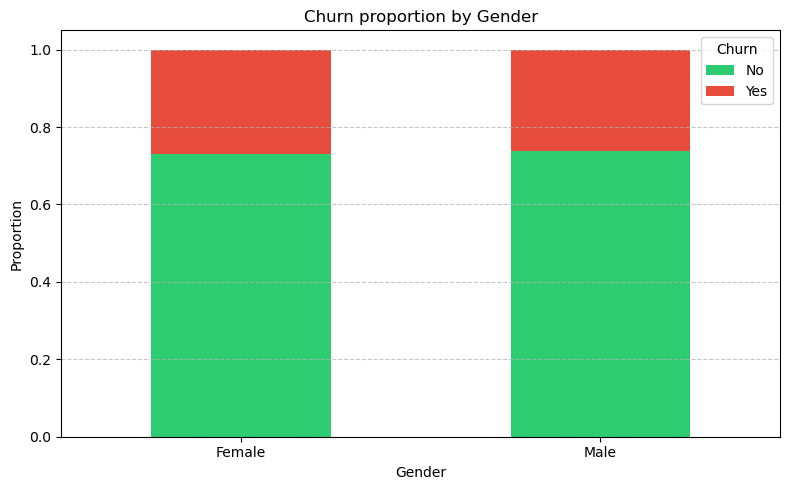

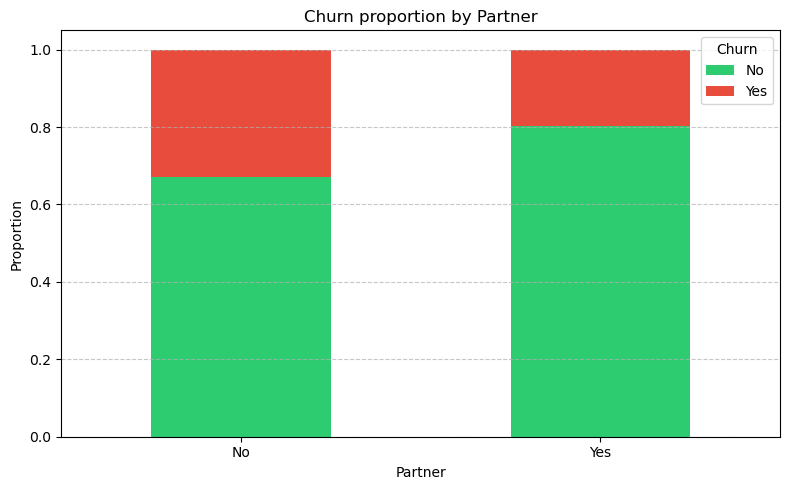

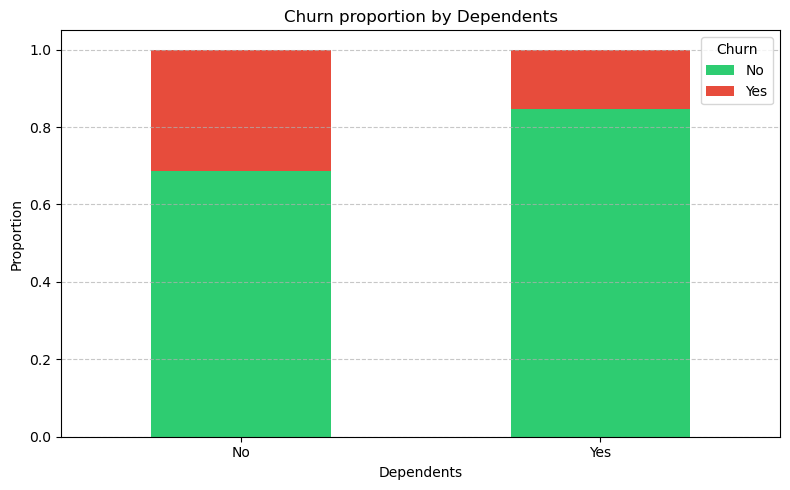

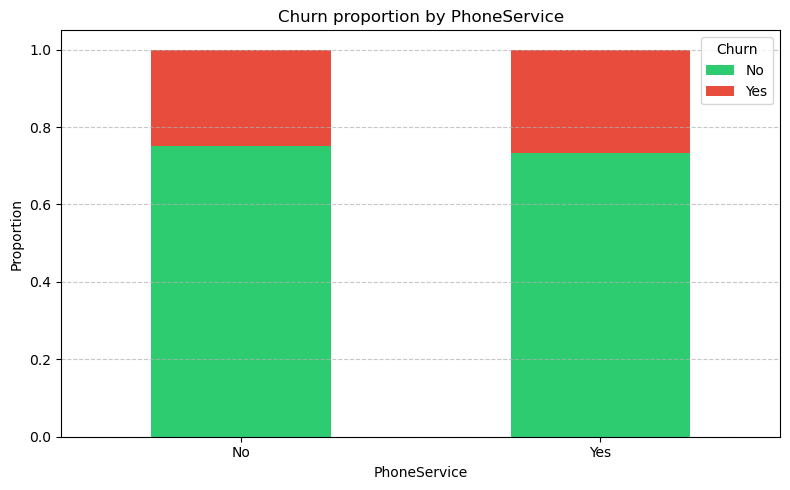

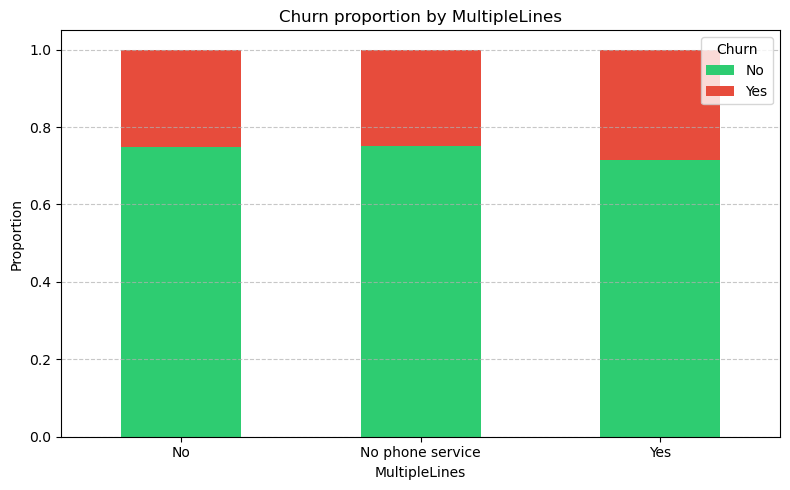

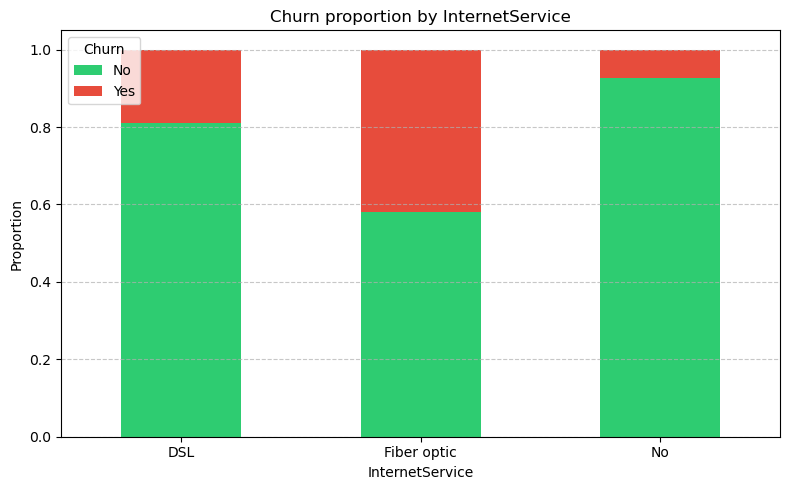

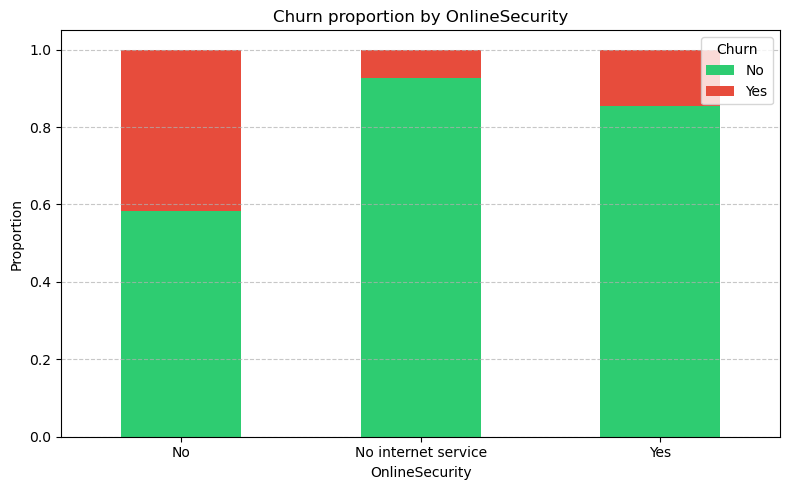

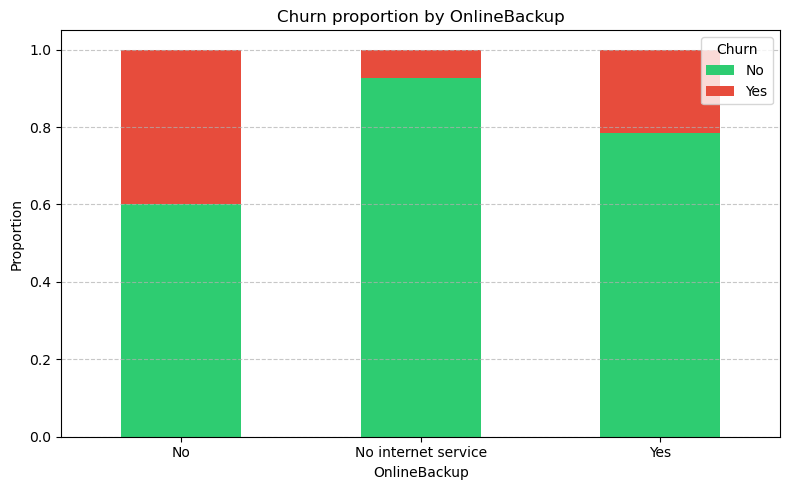

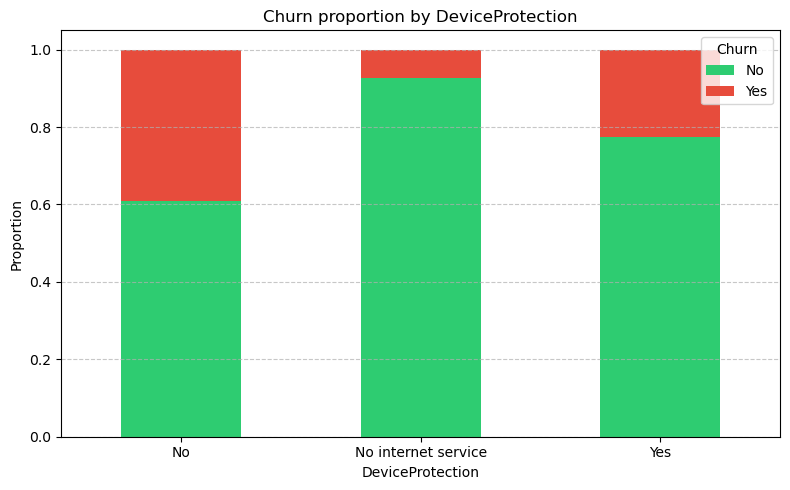

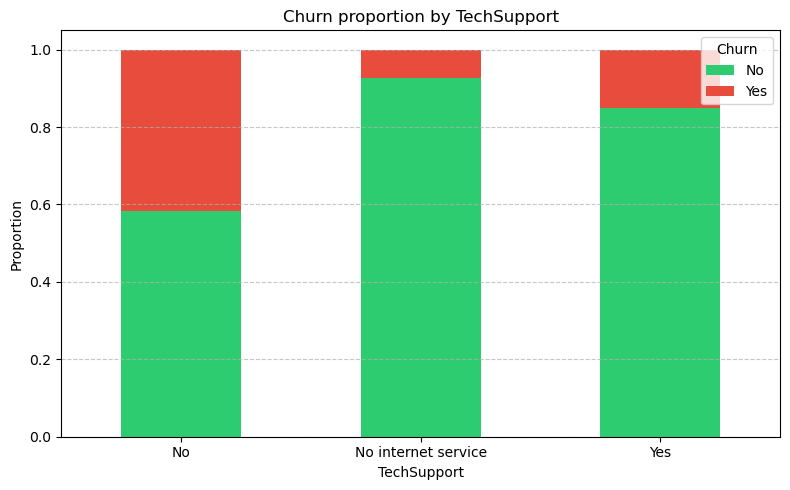

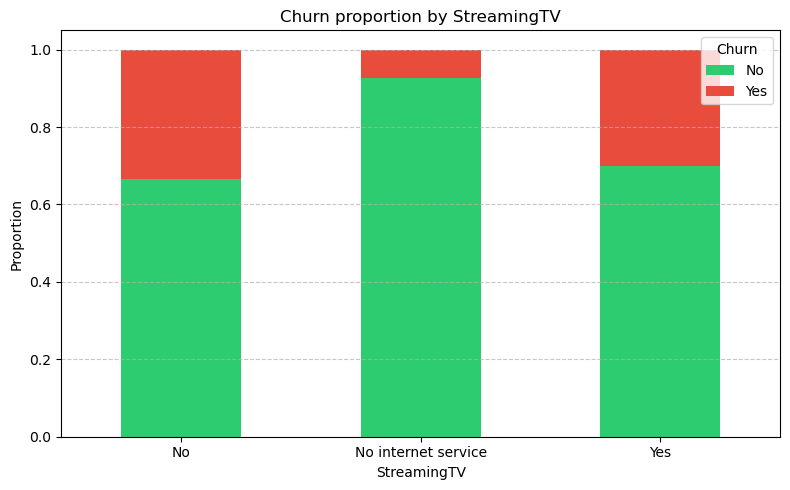

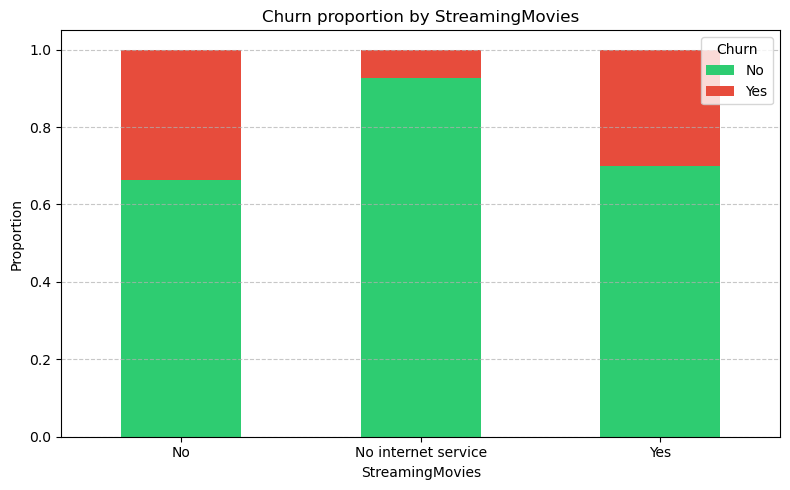

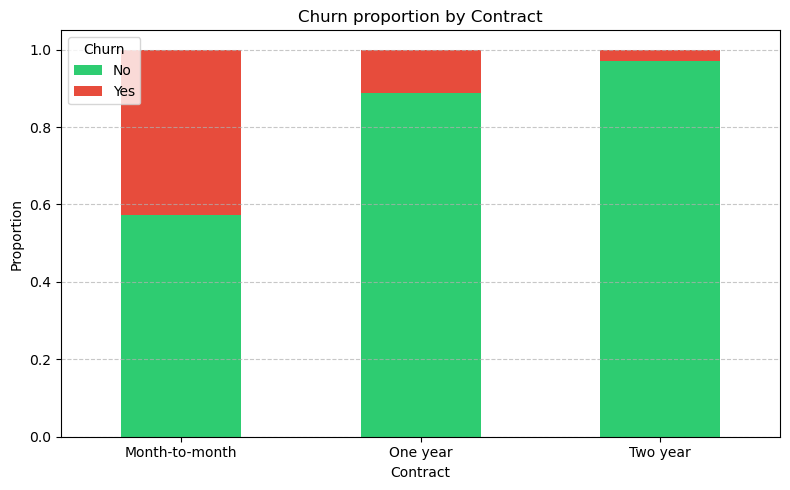

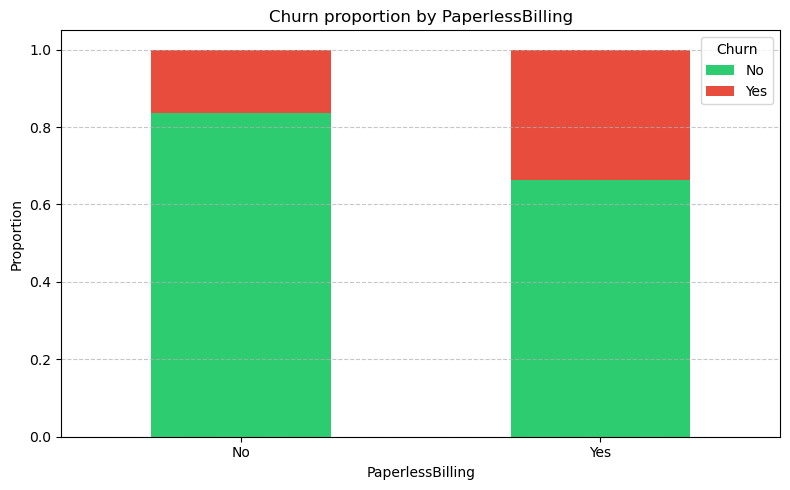

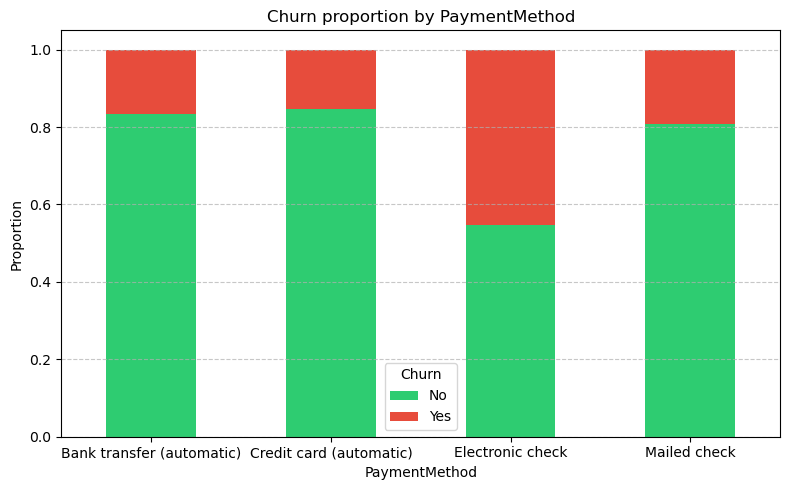

In [19]:
for feature in categorical_features:
    
    if feature == "Churn":
        continue
    
    churn_rate = pd.crosstab(data[feature], data["Churn"], normalize="index")
    
    churn_rate.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5),
        color=["#2ecc71", "#e74c3c"]
    )
    
    plt.title(f"Churn proportion by {feature}")
    plt.ylabel("Proportion")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### Contract

In [20]:
contract_table = pd.crosstab(data["Contract"], data["Churn"])

contract_rate = pd.crosstab(data["Contract"], data["Churn"], normalize="index")

contract_summary = contract_table.join(contract_rate, rsuffix="_rate")

contract_summary.rename(columns={
    "No": "No_count",
    "Yes": "Yes_count",
    "No_rate": "No_rate",
    "Yes_rate": "Churn_rate"
}, inplace=True)

print(contract_summary)

Churn           No_count  Yes_count   No_rate  Churn_rate
Contract                                                 
Month-to-month      2220       1655  0.572903    0.427097
One year            1307        166  0.887305    0.112695
Two year            1647         48  0.971681    0.028319


Churn decreases with the length of the contract.

### Additionnal Services

In [21]:
services = [
    "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport"
]

service_summary = []

for service in services:
    churn_rate = pd.crosstab(data[service], data["Churn"], normalize="index")
    
    service_summary.append({
        "Feature": service,
        "No_service_churn": churn_rate.loc["No", "Yes"],
        "Yes_service_churn": churn_rate.loc["Yes", "Yes"]
    })
    
service_summary = pd.DataFrame(service_summary) ; service_summary

,Feature,No_service_churn,Yes_service_churn
0,OnlineSecurity,0.417667,0.146112
1,OnlineBackup,0.399288,0.215315
2,DeviceProtection,0.391276,0.225021
3,TechSupport,0.416355,0.151663


Churn is always lower with additionnal services, but this is probably a selection bias.

## Numerical features

In [22]:
data.describe()

,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [23]:
data["SeniorCitizen"].head()

0    0
1    0
2    0
3    0
4    0
Name: SeniorCitizen, dtype: int64

In [24]:
numerical_features = data.select_dtypes(include="number").columns

numerical_features = numerical_features.drop("SeniorCitizen")

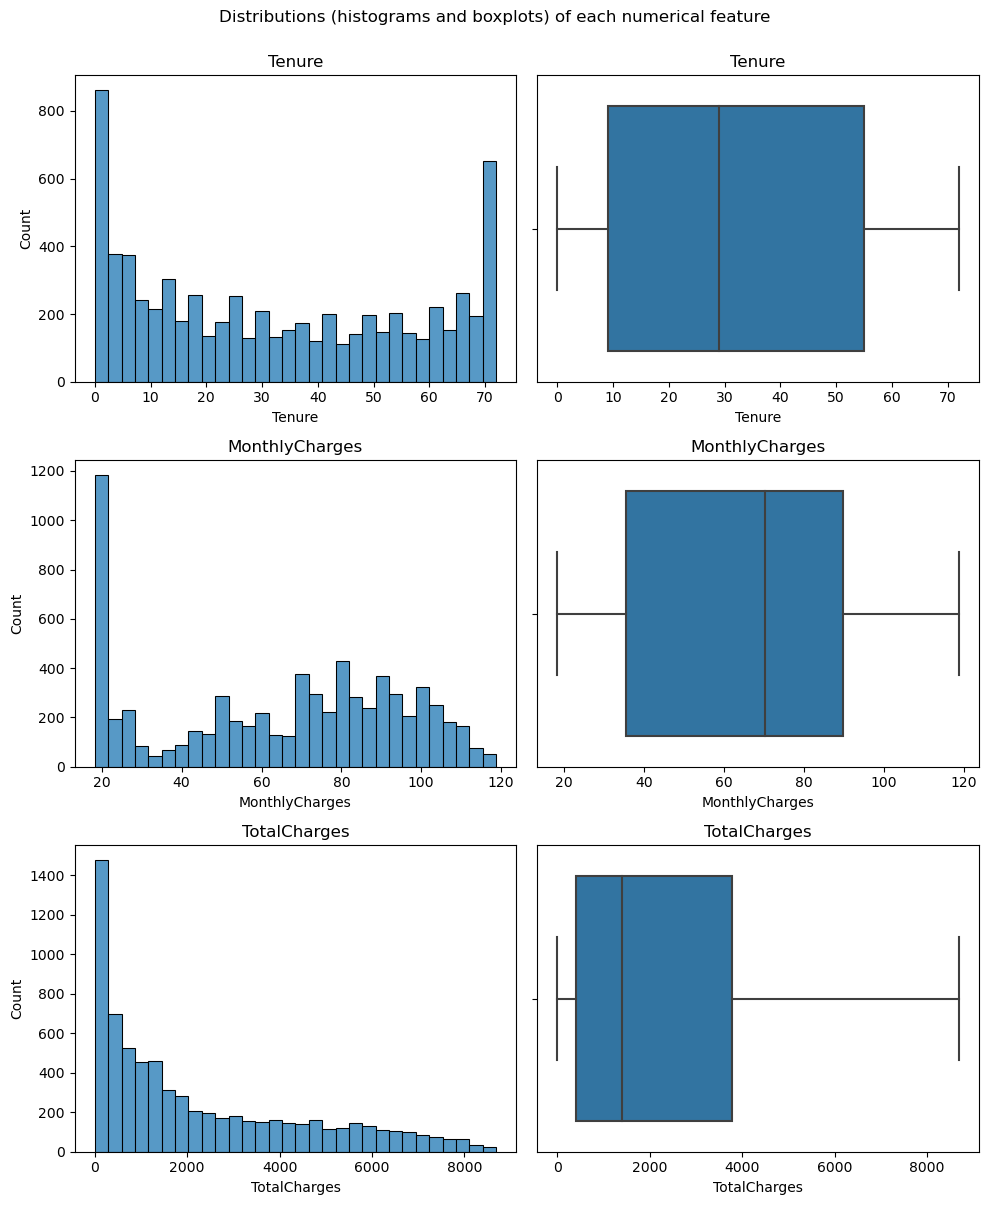

In [25]:
fig, axes = plt.subplots(len(numerical_features),
                        2,
                        figsize=(10, 4 * len(numerical_features)
                        ))

for ax, numerical_feature in zip(axes, numerical_features):
    
    sns.histplot(data[numerical_feature], ax=ax[0], bins=30)
    ax[0].set_title(f"{numerical_feature}")
    
    sns.boxplot(x=data[numerical_feature], ax=ax[1])
    ax[1].set_title(f"{numerical_feature}")
    
plt.suptitle("Distributions (histograms and boxplots) of each numerical feature", y=1)
plt.tight_layout()
plt.show()

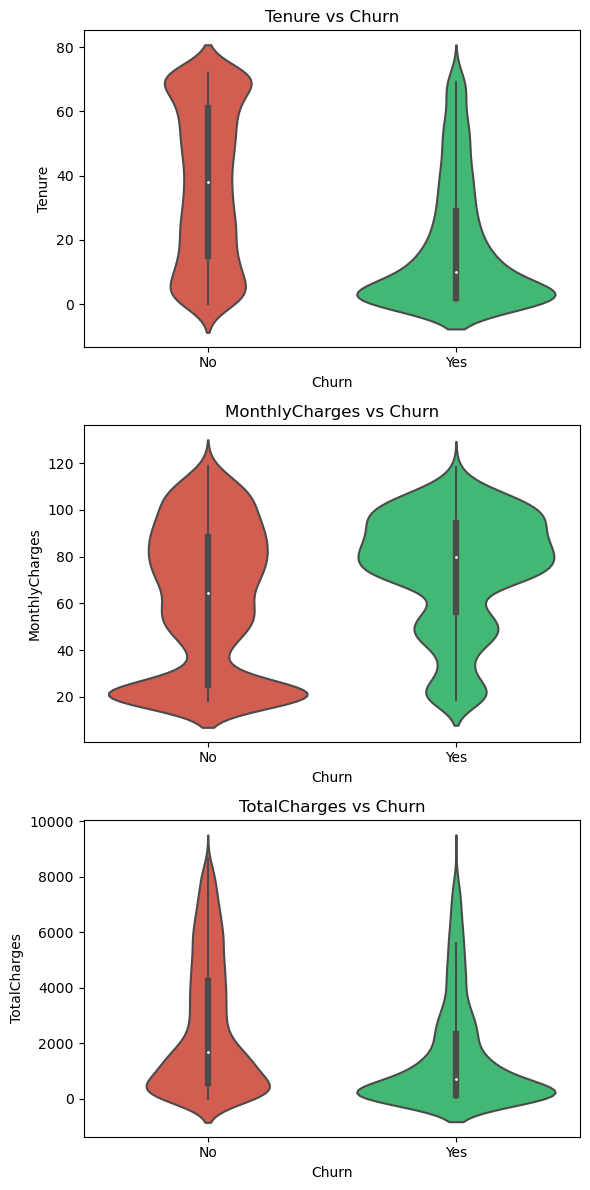

In [26]:
palette = {"Yes": "#2ecc71", "No": "#e74c3c"}

fig, axes = plt.subplots(len(numerical_features),
                         1,
                         figsize=(6, 4 * len(numerical_features)))

for ax, numerical_feature in zip(axes, numerical_features):
    sns.violinplot(data=data, x="Churn", y=numerical_feature, ax=ax, palette=palette)
    ax.set_title(f"{numerical_feature} vs Churn")
    
plt.tight_layout()
plt.show()

## Churn Prediction Modeling

### Data preparation

Let's drop *customerID*:

In [27]:
data = data.drop("customerID", axis=1)

And transform *Churn* into a boolean numerical variable:

In [28]:
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

In [29]:
data["Churn"].head(5)

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

Let's encode the categorical variables:

In [30]:
data_encoded = pd.get_dummies(data, drop_first=True)

In [31]:
data_encoded.head()

,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,Churn,Gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [32]:
X = data_encoded.drop("Churn", axis=1)
y = data_encoded["Churn"]

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

### Baseline Logistic Regression

In [34]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [35]:
y_pred = model.predict(X_test)

In [36]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8183108587650816

Confusion matrix:
[[935 101]
 [155 218]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.58      0.63       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409



In [37]:
y.mean()

0.2653698707936959

In [38]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values("Coefficient", ascending=False)

In [39]:
coefficients.head(15)

,Feature,Coefficient
10,InternetService_Fiber optic,0.549444
26,PaperlessBilling_Yes,0.408621
8,MultipleLines_No phone service,0.273495
23,StreamingMovies_Yes,0.248907
28,PaymentMethod_Electronic check,0.228294
0,SeniorCitizen,0.222620
9,MultipleLines_Yes,0.210252
21,StreamingTV_Yes,0.142310
5,Partner_Yes,0.104734
2,MonthlyCharges,0.004786


In [40]:
coefficients.tail(15)

,Feature,Coefficient
14,OnlineBackup_No internet service,-0.115135
16,DeviceProtection_No internet service,-0.115135
18,TechSupport_No internet service,-0.115135
20,StreamingTV_No internet service,-0.115135
12,OnlineSecurity_No internet service,-0.115135
22,StreamingMovies_No internet service,-0.115135
11,InternetService_No,-0.115135
27,PaymentMethod_Credit card (automatic),-0.128758
6,Dependents_Yes,-0.154045
15,OnlineBackup_Yes,-0.250926


In [41]:
y_proba = model.predict_proba(X_test)[:,1]

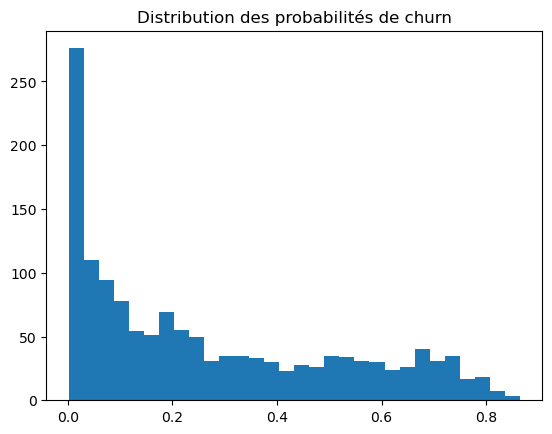

In [42]:
plt.hist(y_proba, bins=30)
plt.title("Distribution des probabilités de churn")
plt.show()

In [43]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [44]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [45]:
y_pred_scaled = model.predict(X_test_scaled)

In [46]:
print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_scaled))
print("\nClassification report:")
print(classification_report(y_test, y_pred_scaled))

Accuracy: 0.8211497515968772

Confusion matrix:
[[934 102]
 [150 223]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



In [47]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values("Coefficient", ascending=False)

In [48]:
coefficients

,Feature,Coefficient
3,TotalCharges,0.655372
10,InternetService_Fiber optic,0.623749
23,StreamingMovies_Yes,0.230218
21,StreamingTV_Yes,0.180597
9,MultipleLines_Yes,0.169279
26,PaperlessBilling_Yes,0.163968
28,PaymentMethod_Electronic check,0.152134
0,SeniorCitizen,0.058754
8,MultipleLines_No phone service,0.035000
17,DeviceProtection_Yes,0.028388


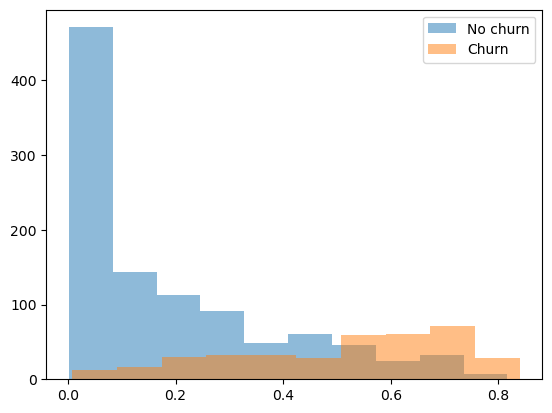

In [49]:
y_proba_scaled = model.predict_proba(X_test_scaled)[:,1]

plt.hist(y_proba_scaled[y_test==0], alpha=0.5, label="No churn")
plt.hist(y_proba_scaled[y_test==1], alpha=0.5, label="Churn")
plt.legend()
plt.show()

After scaling numerical variables, logistic regression achieved an accuracy of 82% and a churn recall of 60%, indicating a solid but imperfect baseline model. The strongest protective factors agains churn are customer tenure and long-term contracts, while fiber optic service, paperless billing, and electronic check payment are associated with higher churn risk.

Probability distributions show that the model separates churn and non-churn, though with substancial overlap, suggesting that churn remains only partially predictable from the available features.

As false negatives are more costly than false positives (missing real churners is more costly than contacting loyal customers), the primary objective is to improve recall, even at the cost of an increase in false positives.

The threshold for churn detection could thus be lowered to 0.3:

In [50]:
threshold = 0.3
y_pred_03 = (y_proba_scaled > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_03))
print("\nClassification report:")
print(classification_report(y_test, y_pred_03))

Accuracy: 0.7764371894960965

Confusion matrix:
[[795 241]
 [ 74 299]]

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      1036
           1       0.55      0.80      0.65       373

    accuracy                           0.78      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.78      0.79      1409



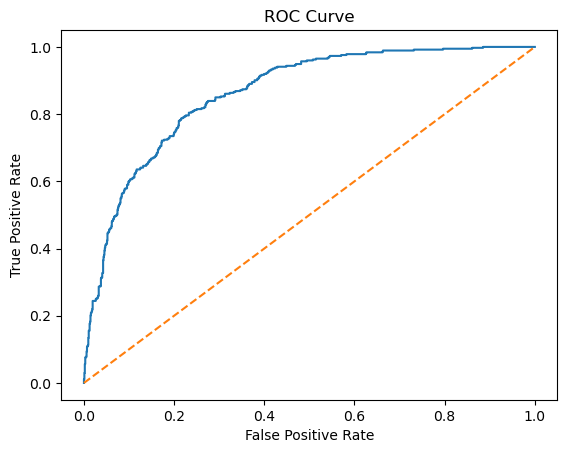

ROC AUC: 0.8621463765565642


In [51]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_scaled)

plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("ROC AUC:", roc_auc_score(y_test, y_proba_scaled))

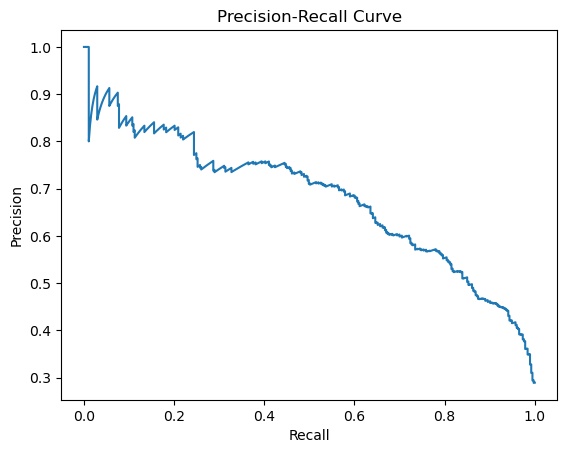

In [52]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_scaled)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

In [53]:
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = []

for t in thresholds:
    y_pred_t = (y_proba_scaled > t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_t))

best_threshold = thresholds[np.argmax(f1_scores)]

print("Best threshold:", best_threshold)
print("Best F1 score:", max(f1_scores))

Best threshold: 0.3199999999999999
Best F1 score: 0.6583990980834273


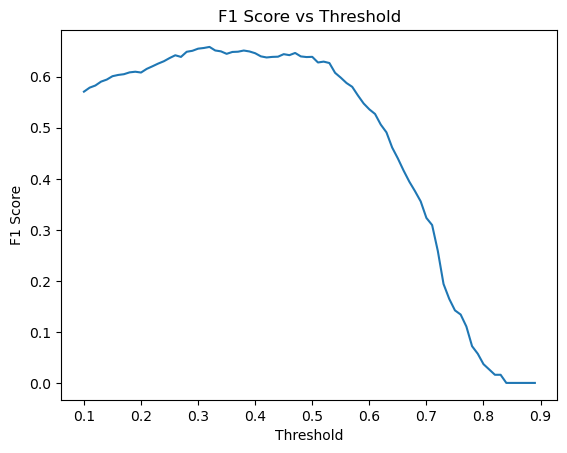

In [54]:
plt.plot(thresholds, f1_scores)
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Threshold")
plt.show()

In [55]:
threshold = max(f1_scores)

y_pred_optimal = (y_proba_scaled > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_optimal))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_optimal))
print("\nClassification report:")
print(classification_report(y_test, y_pred_optimal))

Accuracy: 0.7842441447835344

Confusion matrix:
[[997  39]
 [265 108]]

Classification report:
              precision    recall  f1-score   support

           0       0.79      0.96      0.87      1036
           1       0.73      0.29      0.42       373

    accuracy                           0.78      1409
   macro avg       0.76      0.63      0.64      1409
weighted avg       0.78      0.78      0.75      1409



### More feature engineering

L'effet de Tenure n'est pas purement linéaire. Or, la régression logistique peut mieux capter un pattern si on lui fournit des segments : binning.

In [56]:
data_exp = data.copy()

On peut créer une feature RecentCustomer :

In [57]:
data_exp["RecentCustomer"] = (data_exp["Tenure"] <= 12).astype(int)

data_exp["RecentCustomer"].head()

0    1
1    0
2    1
3    0
4    1
Name: RecentCustomer, dtype: int64

A tester pour MonthlyCharges :

In [58]:
data_exp["HighMonthlyCharges"] = (data_exp["MonthlyCharges"] >= 70).astype(int)

data_exp["HighMonthlyCharges"].head()

0    0
1    0
2    0
3    0
4    1
Name: HighMonthlyCharges, dtype: int64

On peut également attribuer un score par observation en agrégeant des features comme les services :

In [59]:
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]

data_exp["NumServicesYes"] = sum((data_exp[col] == "Yes").astype(int) for col in service_cols)

data_exp["NumServicesYes"].head(15)

0     1
1     2
2     2
3     3
4     0
5     3
6     2
7     1
8     4
9     2
10    1
11    0
12    3
13    4
14    5
Name: NumServicesYes, dtype: int64

Il pourrait être judicieux de prendre en compte les potentielles interactions entre features puisque celles-ci ne sont pas captées naturellement par la régression logistique.

In [60]:
data_exp["ElectronicCheck_Paperless"] = (
    (data_exp["PaymentMethod"] == "Electronic check") &
    (data_exp["PaperlessBilling"] == "Yes")
).astype(int) 

data_exp["ElectronicCheck_Paperless"].head()

0    1
1    0
2    0
3    0
4    1
Name: ElectronicCheck_Paperless, dtype: int64

In [61]:
data_exp_encoded = pd.get_dummies(data_exp, drop_first=True)

X_exp = data_exp_encoded.drop("Churn", axis=1)
y_exp = data_exp_encoded["Churn"]

X_exp_train, X_exp_test, y_exp_train, y_exp_test = train_test_split(
    X_exp, y_exp,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
X_exp_train_scaled = scaler.fit_transform(X_exp_train)
X_exp_test_scaled = scaler.transform(X_exp_test)

model.fit(X_exp_train_scaled, y_exp_train)
y_exp_pred_scaled = model.predict(X_exp_test_scaled)

In [62]:
print("Accuracy:", accuracy_score(y_exp_test, y_exp_pred_scaled))
print("\nConfusion matrix:")
print(confusion_matrix(y_exp_test, y_exp_pred_scaled))
print("\nClassification report:")
print(classification_report(y_exp_test, y_exp_pred_scaled))

Accuracy: 0.8112136266855926

Confusion matrix:
[[934 102]
 [164 209]]

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.88      1036
           1       0.67      0.56      0.61       373

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.81      1409



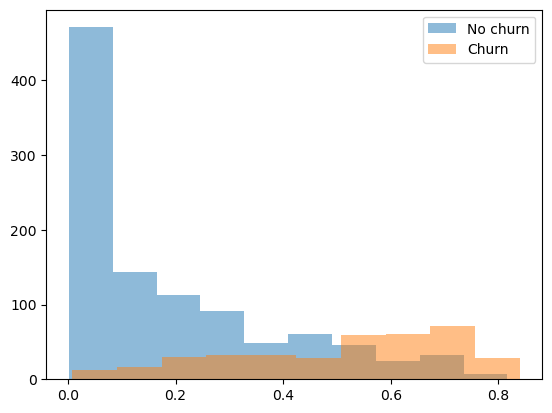

In [63]:
y_exp_proba_scaled = model.predict_proba(X_exp_test_scaled)[:,1]

plt.hist(y_proba_scaled[y_test==0], alpha=0.5, label="No churn")
plt.hist(y_proba_scaled[y_test==1], alpha=0.5, label="Churn")
plt.legend()
plt.show()

In [64]:
threshold = 0.3
y_exp_pred_03 = (y_exp_proba_scaled > threshold).astype(int)

print("Accuracy:", accuracy_score(y_exp_test, y_exp_pred_03))
print("\nConfusion matrix:")
print(confusion_matrix(y_exp_test, y_exp_pred_03))
print("\nClassification report:")
print(classification_report(y_exp_test, y_exp_pred_03))

Accuracy: 0.7693399574166075

Confusion matrix:
[[790 246]
 [ 79 294]]

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1036
           1       0.54      0.79      0.64       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.81      0.77      0.78      1409



On peut directement constater que plus de features ne veut pas dire meilleur modèle. Ici, il y a probablement trop de bruit.

Notammenent probablement dû à la multicolinéarité entre Tenure et RecentCustomer.

### Random Forest

At this point, it seems that customer churn depends on tenure, contract type, services and combinations of those features. Logistic regression is not best suited for cases with interactions, whereas Random Forest capt this naturally.

In [65]:
rf = RandomForestClassifier(
    n_estimators = 100,
    max_depth = None,
    random_state = 42,
    n_jobs =-1
)

In [66]:
rf.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [67]:
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

In [68]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7849538679914834

Confusion matrix:
[[943  93]
 [210 163]]

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1036
           1       0.64      0.44      0.52       373

    accuracy                           0.78      1409
   macro avg       0.73      0.67      0.69      1409
weighted avg       0.77      0.78      0.77      1409



In [69]:
importances = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

importances.head(10)

,Feature,Importance
3,TotalCharges,0.192677
2,MonthlyCharges,0.172247
1,Tenure,0.171681
10,InternetService_Fiber optic,0.037451
28,PaymentMethod_Electronic check,0.035764
25,Contract_Two year,0.029908
13,OnlineSecurity_Yes,0.029213
4,Gender_Male,0.026934
26,PaperlessBilling_Yes,0.025771
19,TechSupport_Yes,0.023863


In [70]:
y_pred_03 = (y_proba > 0.3).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_03))
print("\nClassification report:")
print(classification_report(y_test, y_pred_03))

Accuracy: 0.7693399574166075

Confusion matrix:
[[805 231]
 [ 94 279]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.78      0.83      1036
           1       0.55      0.75      0.63       373

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



In [71]:
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats = 10,
    random_state = 42,
    n_jobs = -1
)

importances_perm = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

importances_perm.head(10)

,Feature,Importance
10,InternetService_Fiber optic,0.008233
1,Tenure,0.006955
25,Contract_Two year,0.001916
24,Contract_One year,-0.000071
19,TechSupport_Yes,-0.000639
13,OnlineSecurity_Yes,-0.001207
28,PaymentMethod_Electronic check,-0.001419
7,PhoneService_Yes,-0.001419
27,PaymentMethod_Credit card (automatic),-0.001419
22,StreamingMovies_No internet service,-0.001845


Le fait que la RF ne soit pas aussi performante indique des relations relativement simples, peu d'interactions complexes et une relation réelle de type paramétrique avec une structure quasi log-linéaire.

La faible importance de Contract_Two et Contract_One vient de leur corrélation entre eux et avec Tenure. L'information est redondante et l'importance est donc diluée.

### XGBoost

Plusieurs des propriétés du boosting en font une bonne méthode pour les données tabulaires et ce cas précis :  
    1. Capte les non-linéarités (churn élevé si tenure très faible puis beaucoup plus faible ensuite  
    2. Capte les interactions entre plusieurs features  
    3. En optimisant les résidus, il prend en compte les zones difficiles du dataset
    
En revanche, il est :   
    1. Sensible au tuning (plus que RF)  
    2. Prompt à l'overfitting (p.e. trop d'arbres trop profonds et avec un learning rate trop important)  
    3. Moins interprétable que les régressions

In [72]:
xgb = XGBClassifier(
    n_estimators = 100,
    max_depth = 3,
    learning_rate = 0.1,
    subsample = 0.8,
    colsample_bytree = 0.8,
    random_state = 42,
    eval_metric = "logloss"
)

In [73]:
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

In [74]:
y_pred = xgb.predict(X_test)
y_proba = xgb.predict_proba(X_test)[:, 1]

In [75]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8197303051809794
[[942  94]
 [160 213]]
              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1036
           1       0.69      0.57      0.63       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409



In [76]:
threshold = 0.3
y_pred_03 = (y_proba > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))
print(confusion_matrix(y_test, y_pred_03))
print(classification_report(y_test, y_pred_03))

Accuracy: 0.7778566359119943
[[794 242]
 [ 71 302]]
              precision    recall  f1-score   support

           0       0.92      0.77      0.84      1036
           1       0.56      0.81      0.66       373

    accuracy                           0.78      1409
   macro avg       0.74      0.79      0.75      1409
weighted avg       0.82      0.78      0.79      1409



#### Hyperparameter tuning (cross validation)

In [77]:
param_dist = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [100, 200, 300],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

search = RandomizedSearchCV(
    xgb,
    param_distributions = param_dist,
    n_iter = 20,
    scoring = "roc_auc",
    cv = 5,
    n_jobs = 1,
    random_state = 42,
    )

search.fit(X_train, y_train)

print(search.best_params_)

{'subsample': 0.6, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


In [78]:
best_xgb = search.best_estimator_

#### Calibration

In [79]:
calibrated_xgb = CalibratedClassifierCV(
    best_xgb,
    method="sigmoid",
    cv=5)

calibrated_xgb.fit(X_train, y_train)

y_proba_cal = calibrated_xgb.predict_proba(X_test)[:, 1]

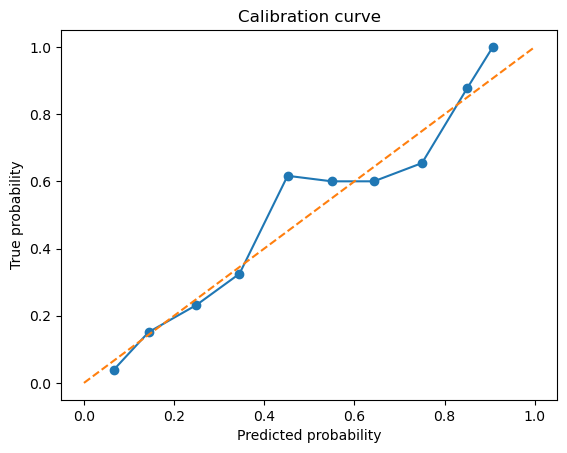

In [80]:
prob_true, prob_pred = calibration_curve(y_test, y_proba_cal, n_bins=10)

plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1],[0,1],'--')
plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.show()

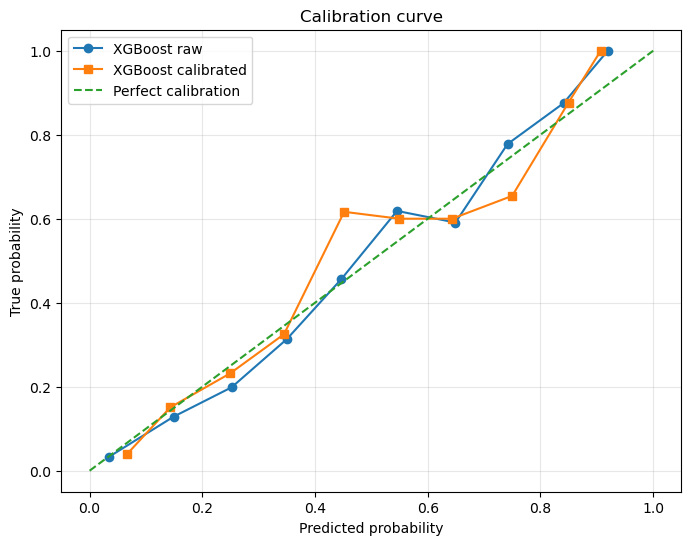

In [81]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_raw, prob_pred_raw = calibration_curve(y_test, y_proba, n_bins=10)
prob_true_cal, prob_pred_cal = calibration_curve(y_test, y_proba_cal, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred_raw, prob_true_raw, marker='o', label="XGBoost raw")
plt.plot(prob_pred_cal, prob_true_cal, marker='s', label="XGBoost calibrated")
plt.plot([0, 1], [0, 1], '--', label="Perfect calibration")

plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Threshold tuning

In [82]:
thresholds = np.arange(0.2, 0.96, 0.01)

results = []

for t in thresholds:
    y_pred_t = (y_proba_cal >= t).astype(int)
    
    results.append({
        "threshold": t,
        "accuracy": accuracy_score(y_test, y_pred_t),
        "precision": precision_score(y_test, y_pred_t, zero_division = 0),
        "recall": recall_score(y_test, y_pred_t),
        "f1": f1_score(y_test, y_pred_t),
    })
    
threshold_df = pd.DataFrame(results)
threshold_df.head()

,threshold,accuracy,precision,recall,f1
0,0.20,0.748758,0.515599,0.841823,0.639511
1,0.21,0.757275,0.526138,0.836461,0.645963
2,0.22,0.765791,0.537262,0.831099,0.652632
3,0.23,0.768630,0.541593,0.820375,0.652452
4,0.24,0.772889,0.547748,0.815013,0.655172


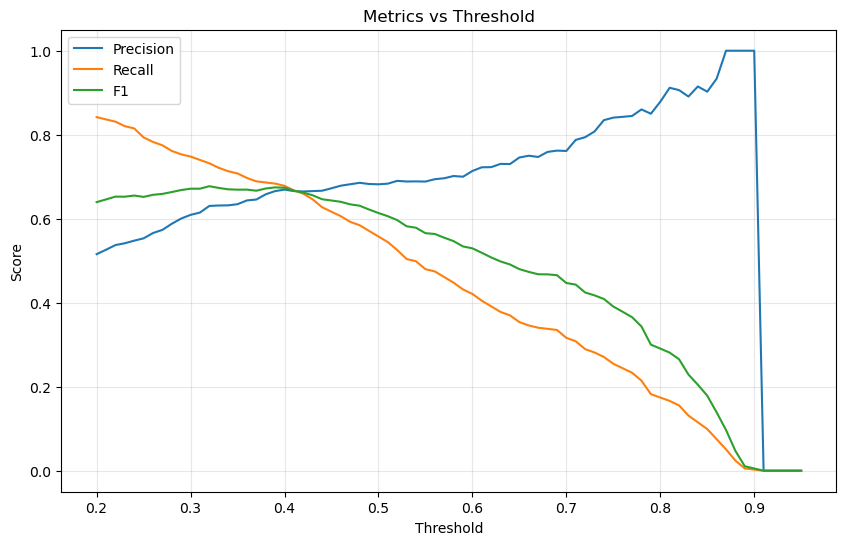

In [83]:
plt.figure(figsize = (10, 6))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label = "Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label = "Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label = "F1")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Metrics vs Threshold")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

In [84]:
candidates = threshold_df[threshold_df["precision"] >= 0.50]
best_recall_row = candidates.loc[candidates["recall"].idxmax()]

In [85]:
threshold = best_recall_row["threshold"]
y_pred_opt = (y_proba_cal > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_opt))
print(confusion_matrix(y_test, y_pred_opt))
print(classification_report(y_test, y_pred_opt))

Accuracy: 0.7487579843860894
[[741 295]
 [ 59 314]]
              precision    recall  f1-score   support

           0       0.93      0.72      0.81      1036
           1       0.52      0.84      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.78      0.72      1409
weighted avg       0.82      0.75      0.76      1409



#### SHAP values

In [86]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

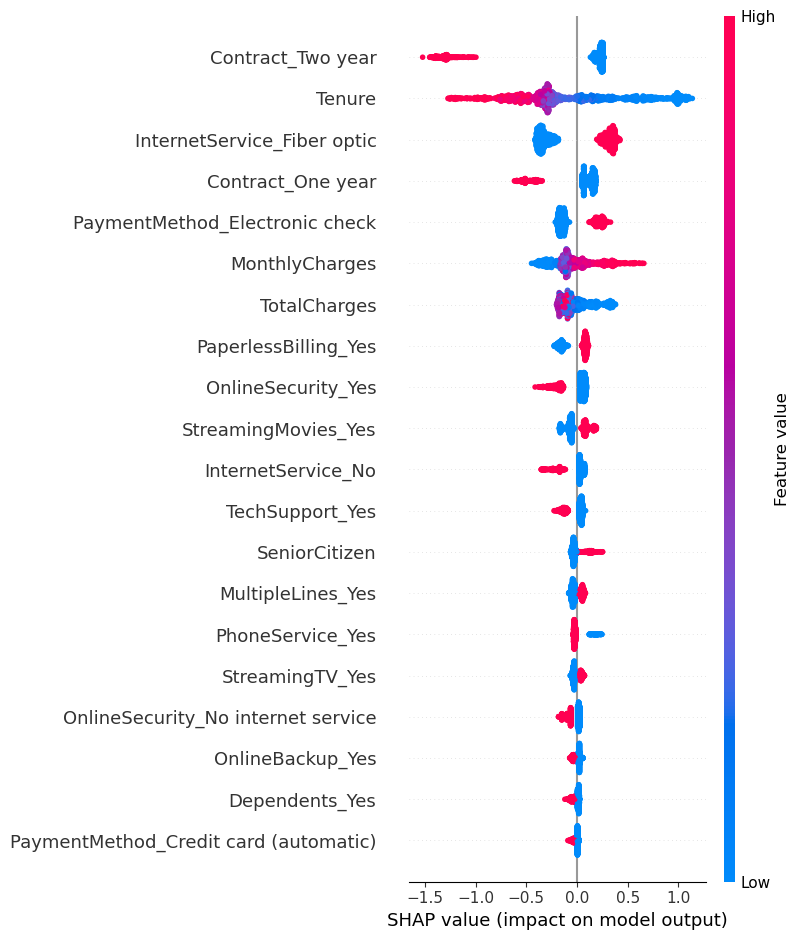

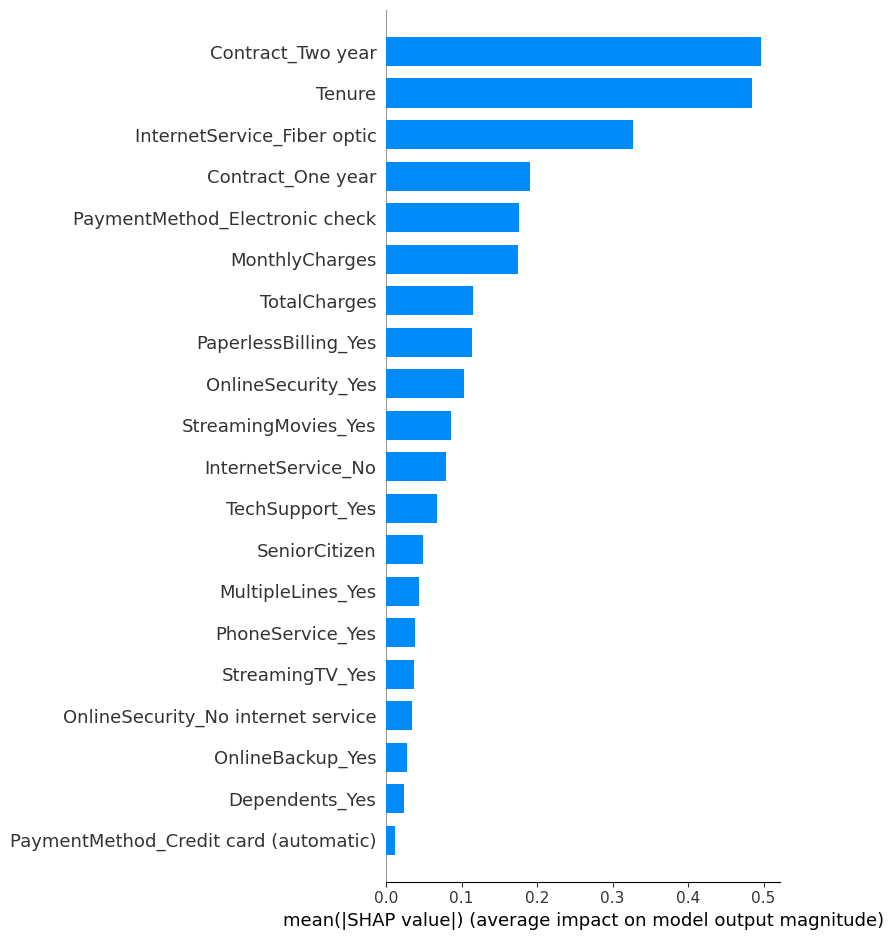

In [87]:
shap.summary_plot(shap_values, X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")

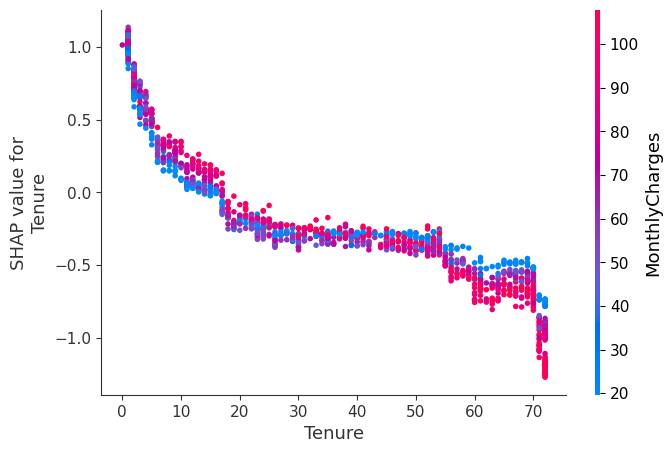

In [88]:
shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X_test.iloc[0]
)

shap.dependence_plot("Tenure", shap_values, X_test)

Customers are significantly more likely to churn during their first months. After this initial period, churn risk decreases sharply and stabilizes, indicating that customer retention strategies should focus on early lifecycle stages.

Add. : no strong interaction, so churn seems to be a tenure problem (duration) much more than a price one.

### Cost-benefit analysis

NameError: name 'strategy_df' is not defined

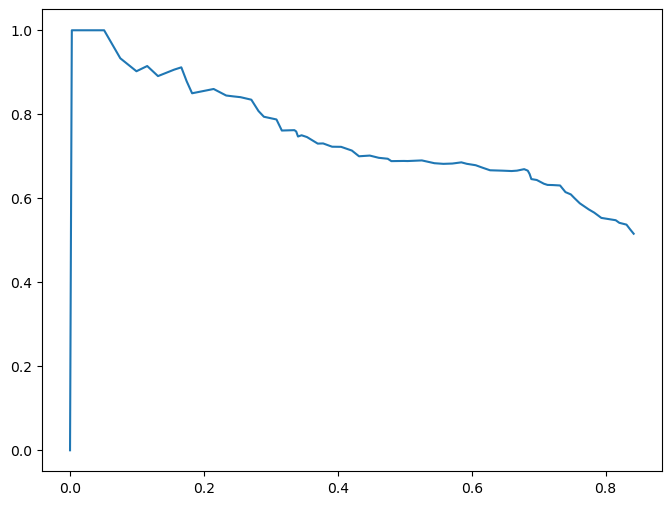

In [89]:
plt.figure(figsize = (8,6))

plt.plot(threshold_df["recall"], threshold_df["precision"], label = "Model curve")

for _, row in strategy_df.iterrows():
    plt.scatter(row["Recall"], row["Precision"])
    plt.text(row["Recall"], row["Precision"], row["Strategy"], fontsize = 9)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision vs Recall trade-off")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

In [90]:
results = []

for name, p_min in strategies.items():
    
    candidates = threshold_df[threshold_df["precision"] >= p_min]
    best_row = candidates.loc[candidates["recall"].idxmax()]
    
    threshold = best_row["threshold"]
    y_pred = (y_proba_cal >= threshold).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    results.append({
        "Strategy": name,
        "Threshold": threshold,
        "TP (churn caught)": tp,
        "FP (wrongly targeted)": fp,
        "FN (missed churn)": fn,
        "Precision": best_row["precision"],
        "Recall": best_row["recall"]
    })

strategy_df = pd.DataFrame(results)
strategy_df

NameError: name 'strategies' is not defined

In [91]:
x = np.arange(len(strategy_df))

plt.figure(figsize = (10,6))

plt.bar(x - 0.2, strategy_df["TP (churn caught)"], width = 0.4, label = "True Positives")
plt.bar(x + 0.2, strategy_df["FP (wrongly targeted)"], width = 0.4, label = "False Positives")

plt.xticks(x, strategy_df["Strategy"], rotation = 20)
plt.ylabel("Number of customers")
plt.title("Business impact of different strategies")
plt.legend()
plt.grid(True, axis = 'y', alpha = 0.3)

plt.show()

NameError: name 'strategy_df' is not defined

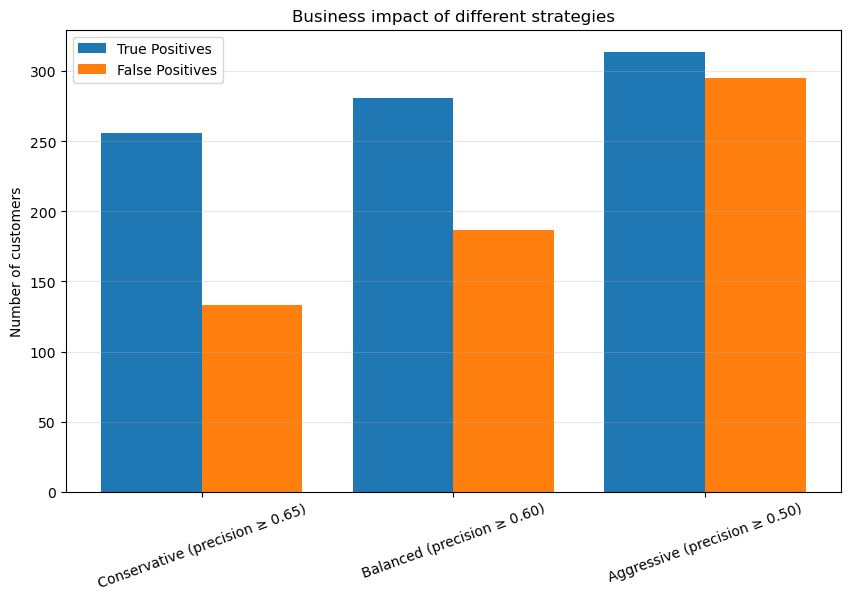

In [167]:
x = np.arange(len(strategy_df))

plt.figure(figsize = (10,6))

plt.bar(x - 0.2, strategy_df["TP (churn caught)"], width = 0.4, label = "True Positives")
plt.bar(x + 0.2, strategy_df["FP (wrongly targeted)"], width = 0.4, label = "False Positives")

plt.xticks(x, strategy_df["Strategy"], rotation = 20)
plt.ylabel("Number of customers")
plt.title("Business impact of different strategies")
plt.legend()
plt.grid(True, axis = 'y', alpha = 0.3)

plt.show()

In [1]:
import sys
print(sys.executable)

/opt/miniconda3/envs/adsmlM1ARM/bin/python


In [2]:
print(sys.version)

3.9.19 | packaged by conda-forge | (main, Mar 20 2024, 12:55:20) 
[Clang 16.0.6 ]
